Corrected RC fit and theory comparison:


,R / Ohm,R_eff / Ohm,u(R_eff) / Ohm,tau_fit / ms,u(tau_fit) / ms,tau_theory / ms,u(tau_theory) / ms,Deviation / %,U_inf / V,t_start / ms
0,220,217.821782,6.226027,0.042210,0.000102,0.047921,0.003087,-11.917621,0.079627,-0.038252
1,1000,956.521739,26.439136,0.184846,0.000223,0.210435,0.013470,-12.159844,0.267480,-0.174507
2,2000,1833.333333,48.713516,0.362258,0.000586,0.403333,0.025634,-10.183946,0.445487,-0.367990
3,10000,6875.000000,149.878219,1.349364,0.003173,1.512500,0.093342,-10.785840,1.567846,-2.722768
4,20000,10476.190476,214.086659,1.939186,0.005564,2.304762,0.141155,-15.861760,2.393470,-0.818994


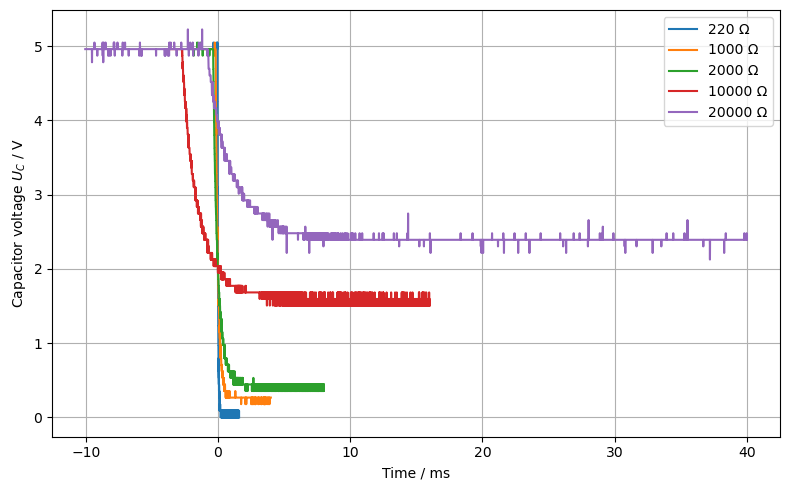

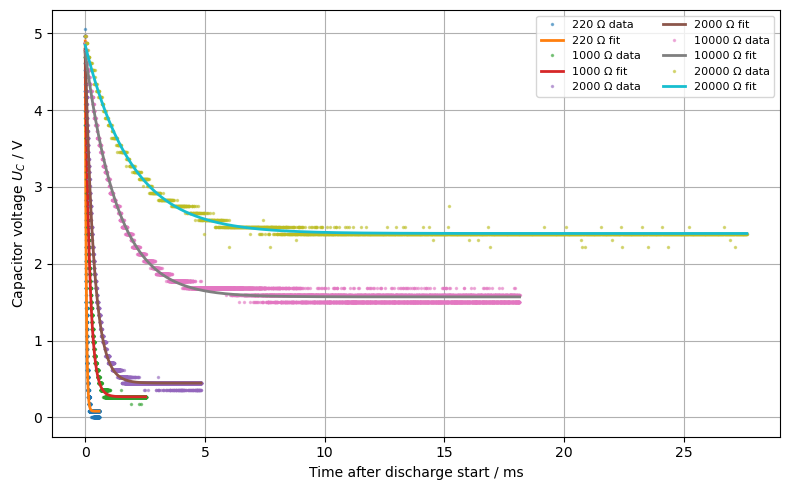

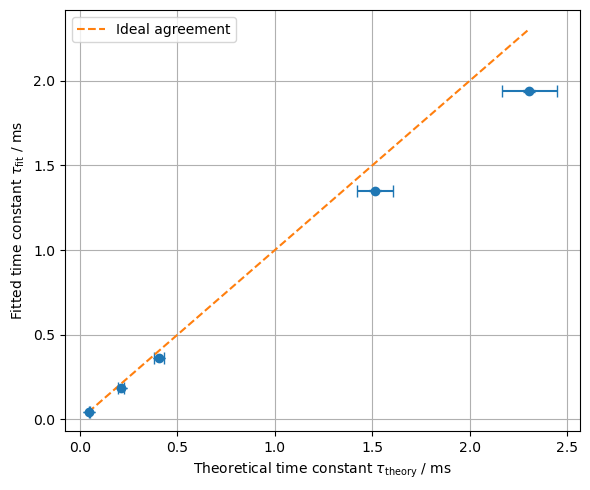

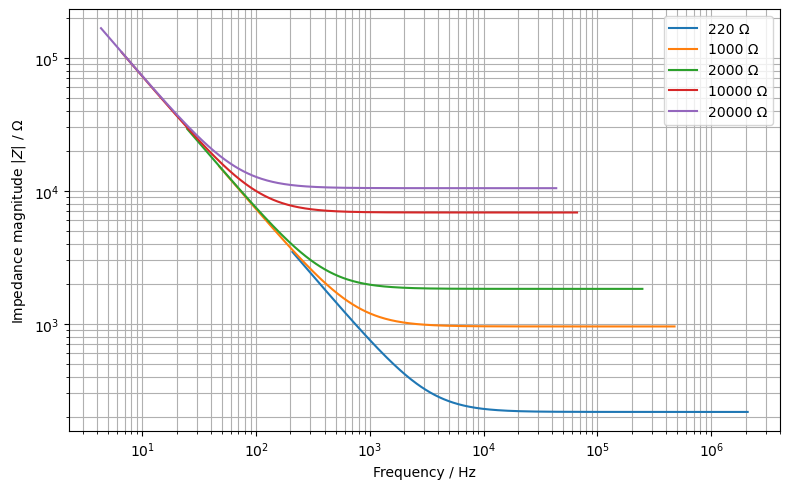

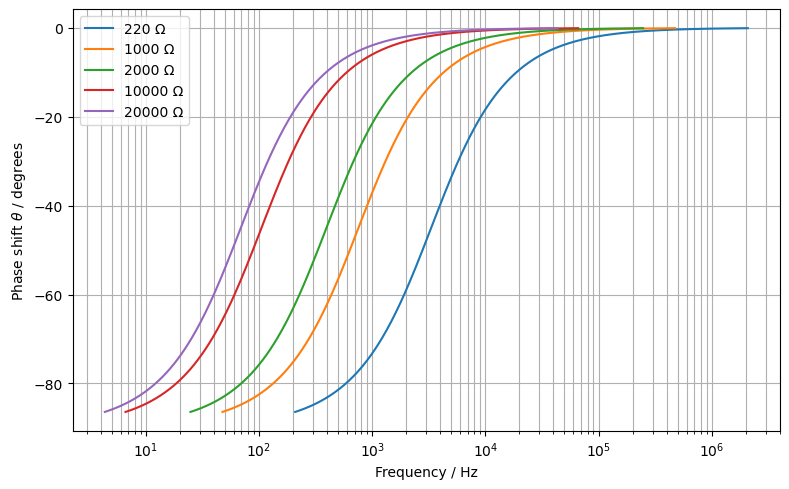

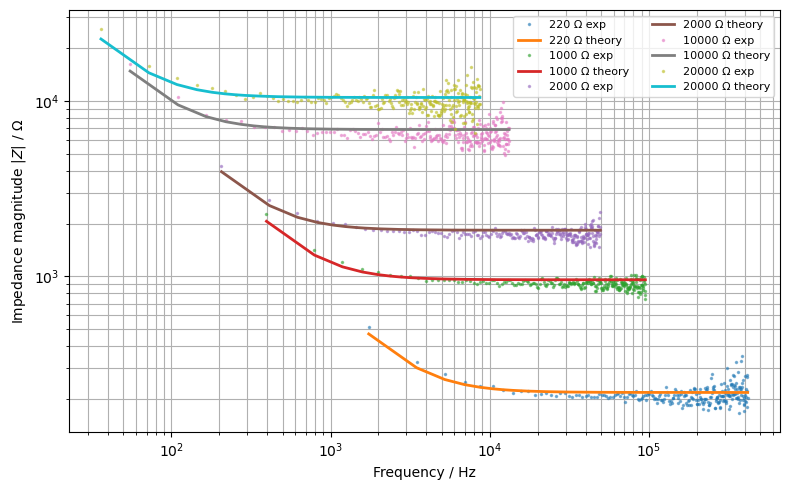

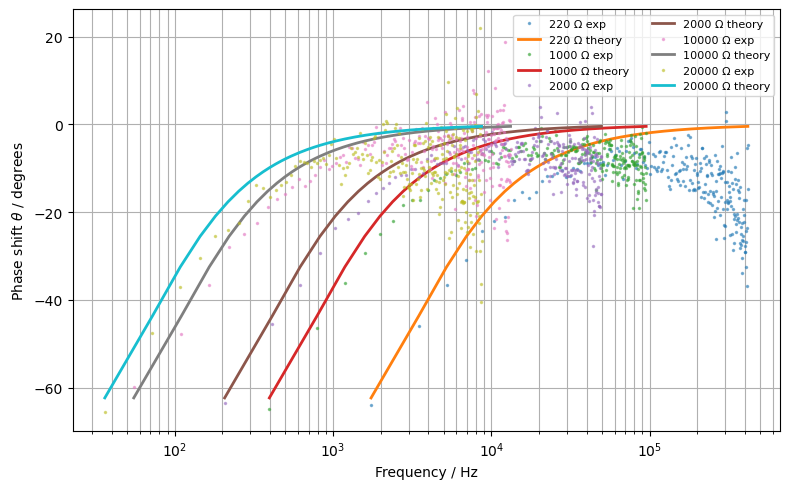


LaTeX table:
\begin{tabular}{lllllll}
\toprule
$R/\Omega$ & $R_\mathrm{eff}/\Omega$ & $\tau_\mathrm{fit}/\mathrm{ms}$ & $u(\tau_\mathrm{fit})/\mathrm{ms}$ & $\tau_\mathrm{theory}/\mathrm{ms}$ & $u(\tau_\mathrm{theory})/\mathrm{ms}$ & Deviation/\% \\
\midrule
220 & 217.8 & 0.042 & 0.000 & 0.048 & 0.003 & -11.92 \\
1000 & 956.5 & 0.185 & 0.000 & 0.210 & 0.013 & -12.16 \\
2000 & 1833.3 & 0.362 & 0.001 & 0.403 & 0.026 & -10.18 \\
10000 & 6875.0 & 1.349 & 0.003 & 1.513 & 0.093 & -10.79 \\
20000 & 10476.2 & 1.939 & 0.006 & 2.305 & 0.141 & -15.86 \\
\bottomrule
\end{tabular}


Saved files:
task1_rc_corrected_results.csv
task1_rc_raw_curves.png
task1_rc_exponential_fits.png
task1_rc_tau_comparison.png
task1_rc_impedance_theory.png
task1_rc_phase_theory.png
task1_rc_impedance_fft.png
task1_rc_phase_fft.png
task1_rc_latex_table.txt


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

# -----------------------------
# Constants
# -----------------------------

C = 220e-9                  # F
u_C = 0.10 * C / np.sqrt(3) # 10% assumed capacitor tolerance

R_ch = 22e3                 # Ohm
u_R_ch = 0.05 * R_ch / np.sqrt(3)

files = {
    220: "1_220.csv",
    1000: "1_1k.csv",
    2000: "1_2k.csv",
    10000: "1_10k.csv",
    20000: "1_20k.csv"
}

# -----------------------------
# Helper functions
# -----------------------------

def read_picoscope_csv(filename):
    """
    Reads PicoScope CSV files with structure:
    Time, Channel A
    (ms), (V)

    Time is converted from ms to seconds.
    """
    df = pd.read_csv(filename, skiprows=[1, 2])
    t_ms = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy()
    V = pd.to_numeric(df.iloc[:, 1], errors="coerce").to_numpy()

    mask = np.isfinite(t_ms) & np.isfinite(V)
    t = t_ms[mask] * 1e-3  # ms to s
    V = V[mask]

    return t, V


def rc_model(t, U_inf, A, tau):
    return U_inf + A * np.exp(-t / tau)


def effective_parallel_resistance(R, R_ch):
    return (R * R_ch) / (R + R_ch)


def uncertainty_parallel_resistance(R, u_R, R_ch, u_R_ch):
    denom = (R + R_ch)**2
    dReff_dR = R_ch**2 / denom
    dReff_dRch = R**2 / denom

    return np.sqrt((dReff_dR * u_R)**2 + (dReff_dRch * u_R_ch)**2)


def find_discharge_start(t, V):
    """
    Finds the start of discharge using a rolling threshold.
    This is more stable than using the largest negative slope.
    """
    n = len(V)

    high = np.median(V[:max(50, n // 20)])
    low = np.median(V[-max(50, n // 20)])

    # Start when signal has dropped by 2% of the full voltage difference
    threshold = high - 0.02 * (high - low)

    window = max(5, n // 500)
    kernel = np.ones(window) / window
    V_smooth = np.convolve(V, kernel, mode="valid")

    indices = np.where(V_smooth < threshold)[0]

    if len(indices) == 0:
        return 0

    return int(indices[0])


def fit_rc_curve(t, V, R_eff, C, fit_window_factor=12):
    """
    Fits the discharge curve with:
    U_C(t) = U_inf + A exp(-t/tau)

    Only the first fit_window_factor * tau_theory is used.
    """
    tau_theory = R_eff * C

    start_idx = find_discharge_start(t, V)
    t_start = t[start_idx]

    mask = (t >= t_start) & (t <= t_start + fit_window_factor * tau_theory)

    t_fit = t[mask] - t_start
    V_fit = V[mask]

    if len(t_fit) < 20:
        raise RuntimeError("Too few points selected for fitting.")

    U_inf_guess = np.median(V_fit[-max(10, len(V_fit)//10):])
    A_guess = V_fit[0] - U_inf_guess
    tau_guess = tau_theory

    p0 = [U_inf_guess, A_guess, tau_guess]

    lower = [-20, -20, 0.02 * tau_theory]
    upper = [20, 20, 50 * tau_theory]

    popt, pcov = curve_fit(
        rc_model,
        t_fit,
        V_fit,
        p0=p0,
        bounds=(lower, upper),
        maxfev=50000
    )

    perr = np.sqrt(np.diag(pcov))

    return t_fit, V_fit, popt, perr, t_start


def rc_impedance(freq, R_eff, C):
    omega = 2 * np.pi * freq
    return R_eff + 1 / (1j * omega * C)

# -----------------------------
# Fit all curves
# -----------------------------

results = []
data = {}

for R, filename in files.items():
    t, V = read_picoscope_csv(filename)

    u_R = 0.05 * R / np.sqrt(3)

    R_eff = effective_parallel_resistance(R, R_ch)
    u_R_eff = uncertainty_parallel_resistance(R, u_R, R_ch, u_R_ch)

    t_fit, V_fit, popt, perr, t_start = fit_rc_curve(t, V, R_eff, C)

    U_inf, A, tau_fit = popt
    u_U_inf, u_A, u_tau_fit = perr

    tau_theory = R_eff * C
    u_tau_theory = tau_theory * np.sqrt((u_R_eff / R_eff)**2 + (u_C / C)**2)

    deviation = (tau_fit - tau_theory) / tau_theory * 100

    results.append({
        "R / Ohm": R,
        "R_eff / Ohm": R_eff,
        "u(R_eff) / Ohm": u_R_eff,
        "tau_fit / ms": tau_fit * 1e3,
        "u(tau_fit) / ms": u_tau_fit * 1e3,
        "tau_theory / ms": tau_theory * 1e3,
        "u(tau_theory) / ms": u_tau_theory * 1e3,
        "Deviation / %": deviation,
        "U_inf / V": U_inf,
        "t_start / ms": t_start * 1e3
    })

    data[R] = {
        "t_raw": t,
        "V_raw": V,
        "t_fit": t_fit,
        "V_fit": V_fit,
        "popt": popt,
        "perr": perr,
        "R_eff": R_eff,
        "u_R_eff": u_R_eff
    }

results_df = pd.DataFrame(results)

print("Corrected RC fit and theory comparison:")
display(results_df)

results_df.to_csv("task1_rc_corrected_results.csv", index=False)

# -----------------------------
# Plot 1: Raw curves
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    plt.plot(data[R]["t_raw"] * 1e3, data[R]["V_raw"], label=f"{R:g} Ω")

plt.xlabel("Time / ms")
plt.ylabel("Capacitor voltage $U_C$ / V")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("task1_rc_raw_curves.png", dpi=300)
plt.show()

# -----------------------------
# Plot 2: Exponential fits
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    t_fit = data[R]["t_fit"]
    V_fit = data[R]["V_fit"]
    U_inf, A, tau = data[R]["popt"]

    plt.plot(t_fit * 1e3, V_fit, ".", markersize=3, alpha=0.5, label=f"{R:g} Ω data")

    t_smooth = np.linspace(t_fit.min(), t_fit.max(), 1000)
    V_smooth = rc_model(t_smooth, U_inf, A, tau)

    plt.plot(t_smooth * 1e3, V_smooth, "-", linewidth=2, label=f"{R:g} Ω fit")

plt.xlabel("Time after discharge start / ms")
plt.ylabel("Capacitor voltage $U_C$ / V")
plt.grid(True)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task1_rc_exponential_fits.png", dpi=300)
plt.show()

# -----------------------------
# Plot 3: tau comparison
# -----------------------------

plt.figure(figsize=(6, 5))

plt.errorbar(
    results_df["tau_theory / ms"],
    results_df["tau_fit / ms"],
    xerr=results_df["u(tau_theory) / ms"],
    yerr=results_df["u(tau_fit) / ms"],
    fmt="o",
    capsize=4
)

min_val = min(results_df["tau_theory / ms"].min(), results_df["tau_fit / ms"].min())
max_val = max(results_df["tau_theory / ms"].max(), results_df["tau_fit / ms"].max())

plt.plot([min_val, max_val], [min_val, max_val], "--", label="Ideal agreement")

plt.xlabel(r"Theoretical time constant $\tau_\mathrm{theory}$ / ms")
plt.ylabel(r"Fitted time constant $\tau_\mathrm{fit}$ / ms")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("task1_rc_tau_comparison.png", dpi=300)
plt.show()

# -----------------------------
# Plot 4: RC impedance theory
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    R_eff = data[R]["R_eff"]
    tau = R_eff * C

    f_min = 1 / (100 * tau)
    f_max = 100 / tau

    freq = np.logspace(np.log10(f_min), np.log10(f_max), 500)
    Z = rc_impedance(freq, R_eff, C)

    plt.loglog(freq, np.abs(Z), label=f"{R:g} Ω")

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Impedance magnitude $|Z|$ / $\Omega$")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("task1_rc_impedance_theory.png", dpi=300)
plt.show()

# -----------------------------
# Plot 5: RC phase theory
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    R_eff = data[R]["R_eff"]
    tau = R_eff * C

    f_min = 1 / (100 * tau)
    f_max = 100 / tau

    freq = np.logspace(np.log10(f_min), np.log10(f_max), 500)
    Z = rc_impedance(freq, R_eff, C)

    plt.semilogx(freq, np.angle(Z, deg=True), label=f"{R:g} Ω")

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Phase shift $\theta$ / degrees")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("task1_rc_phase_theory.png", dpi=300)
plt.show()

# -----------------------------
# FFT-based impedance and phase
# -----------------------------

fft_data = {}

for R in files:
    t_fit = data[R]["t_fit"]
    V_fit = data[R]["V_fit"]
    U_inf, A, tau_fit = data[R]["popt"]
    R_eff = data[R]["R_eff"]

    dt = np.mean(np.diff(t_fit))

    # Normalized discharge function
    fD = (V_fit - U_inf) / A

    # Remove small remaining offset
    fD = fD - np.mean(fD[-max(10, len(fD)//10):])

    freq = np.fft.rfftfreq(len(fD), d=dt)
    fhat = np.fft.rfft(fD) * dt

    valid = freq > 0
    freq = freq[valid]
    fhat = fhat[valid]

    omega = 2 * np.pi * freq

    Z_exp = R_eff / (1j * omega * fhat)
    Z_theory = rc_impedance(freq, R_eff, C)

    fft_data[R] = {
        "freq": freq,
        "Z_exp": Z_exp,
        "Z_theory": Z_theory
    }

# -----------------------------
# Plot 6: FFT impedance
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    freq = fft_data[R]["freq"]
    Z_exp = fft_data[R]["Z_exp"]
    Z_theory = fft_data[R]["Z_theory"]

    R_eff = data[R]["R_eff"]
    tau = R_eff * C

    f_min = 1 / (20 * tau)
    f_max = 20 / tau

    mask = (freq >= f_min) & (freq <= f_max)

    plt.loglog(freq[mask], np.abs(Z_exp[mask]), ".", markersize=3, alpha=0.5, label=f"{R:g} Ω exp")
    plt.loglog(freq[mask], np.abs(Z_theory[mask]), "-", linewidth=2, label=f"{R:g} Ω theory")

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Impedance magnitude $|Z|$ / $\Omega$")
plt.grid(True, which="both")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task1_rc_impedance_fft.png", dpi=300)
plt.show()

# -----------------------------
# Plot 7: FFT phase
# -----------------------------

plt.figure(figsize=(8, 5))

for R in files:
    freq = fft_data[R]["freq"]
    Z_exp = fft_data[R]["Z_exp"]
    Z_theory = fft_data[R]["Z_theory"]

    R_eff = data[R]["R_eff"]
    tau = R_eff * C

    f_min = 1 / (20 * tau)
    f_max = 20 / tau

    mask = (freq >= f_min) & (freq <= f_max)

    plt.semilogx(freq[mask], np.angle(Z_exp[mask], deg=True), ".", markersize=3, alpha=0.5, label=f"{R:g} Ω exp")
    plt.semilogx(freq[mask], np.angle(Z_theory[mask], deg=True), "-", linewidth=2, label=f"{R:g} Ω theory")

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Phase shift $\theta$ / degrees")
plt.grid(True, which="both")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task1_rc_phase_fft.png", dpi=300)
plt.show()

# -----------------------------
# LaTeX table
# -----------------------------

latex_df = results_df.copy()

latex_df["R / Ohm"] = latex_df["R / Ohm"].map(lambda x: f"{x:.0f}")
latex_df["R_eff / Ohm"] = latex_df["R_eff / Ohm"].map(lambda x: f"{x:.1f}")
latex_df["tau_fit / ms"] = latex_df["tau_fit / ms"].map(lambda x: f"{x:.3f}")
latex_df["u(tau_fit) / ms"] = latex_df["u(tau_fit) / ms"].map(lambda x: f"{x:.3f}")
latex_df["tau_theory / ms"] = latex_df["tau_theory / ms"].map(lambda x: f"{x:.3f}")
latex_df["u(tau_theory) / ms"] = latex_df["u(tau_theory) / ms"].map(lambda x: f"{x:.3f}")
latex_df["Deviation / %"] = latex_df["Deviation / %"].map(lambda x: f"{x:.2f}")

latex_df = latex_df[[
    "R / Ohm",
    "R_eff / Ohm",
    "tau_fit / ms",
    "u(tau_fit) / ms",
    "tau_theory / ms",
    "u(tau_theory) / ms",
    "Deviation / %"
]]

latex_df.columns = [
    r"$R/\Omega$",
    r"$R_\mathrm{eff}/\Omega$",
    r"$\tau_\mathrm{fit}/\mathrm{ms}$",
    r"$u(\tau_\mathrm{fit})/\mathrm{ms}$",
    r"$\tau_\mathrm{theory}/\mathrm{ms}$",
    r"$u(\tau_\mathrm{theory})/\mathrm{ms}$",
    r"Deviation/\%"
]

latex_code = latex_df.to_latex(index=False, escape=False)

with open("task1_rc_latex_table.txt", "w") as f:
    f.write(latex_code)

print("\nLaTeX table:")
print(latex_code)

print("\nSaved files:")
print("task1_rc_corrected_results.csv")
print("task1_rc_raw_curves.png")
print("task1_rc_exponential_fits.png")
print("task1_rc_tau_comparison.png")
print("task1_rc_impedance_theory.png")
print("task1_rc_phase_theory.png")
print("task1_rc_impedance_fft.png")
print("task1_rc_phase_fft.png")
print("task1_rc_latex_table.txt")

Task 2 RLC fit results:


,R / Ohm,u(R) / Ohm,delta / 1/s,u(delta) / 1/s,omega_d / rad/s,u(omega_d) / rad/s,f_d / kHz,omega_0 / rad/s,f_0 / kHz,L / mH,u(L) / mH,U_off / V,A / V,phi / rad,t_start / us,R_sp / Ohm,u(R_sp) / Ohm
0,10,0.288675,50474.256433,96.904405,1.039925e+06,100.244328,165.509269,1.041150e+06,165.704107,0.922516,0.053262,0.007478,3.601240,-1.084468,4.567092,83.206043,2.430496
1,20,0.577350,55763.943638,94.214531,1.035789e+06,89.271583,164.850985,1.037289e+06,165.089717,0.929395,0.053659,0.012513,4.439823,0.972664,0.434140,82.974009,2.726382
2,100,2.886751,95261.791384,155.482828,1.034360e+06,166.309373,164.623503,1.038737e+06,165.320191,0.926805,0.053510,0.028946,4.828269,-0.250933,-0.720136,75.910955,5.389517
3,220,6.350853,153486.575815,212.619554,1.032056e+06,242.467628,164.256810,1.043407e+06,166.063343,0.918529,0.053033,0.063602,4.908358,-0.296233,-0.746625,63.429167,9.697717
4,320,9.237604,206514.077151,258.666249,1.022227e+06,315.199108,162.692526,1.042879e+06,165.979354,0.919458,0.053088,0.086093,5.074345,-0.369706,-0.785709,61.350047,13.509986



Estimated mean inductance:
L = 0.9233 mH
u(L) ≈ 0.0238 mH

Estimated coil internal resistance:
R_sp = 73.37 Ohm
scatter ≈ 10.47 Ohm


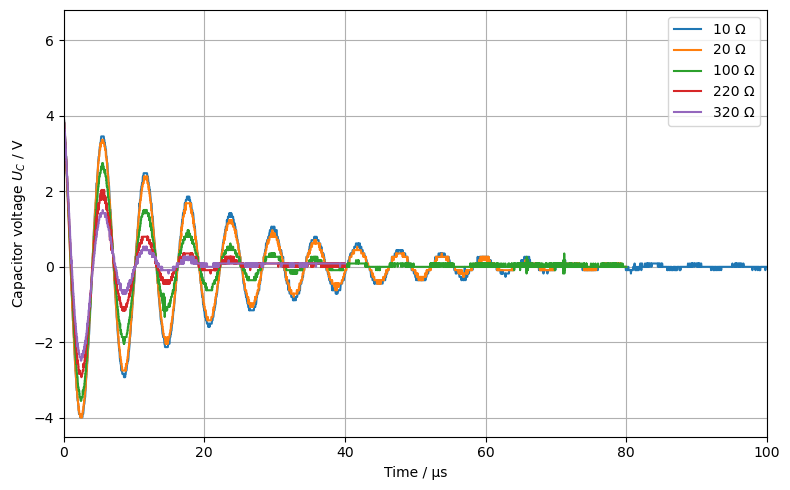

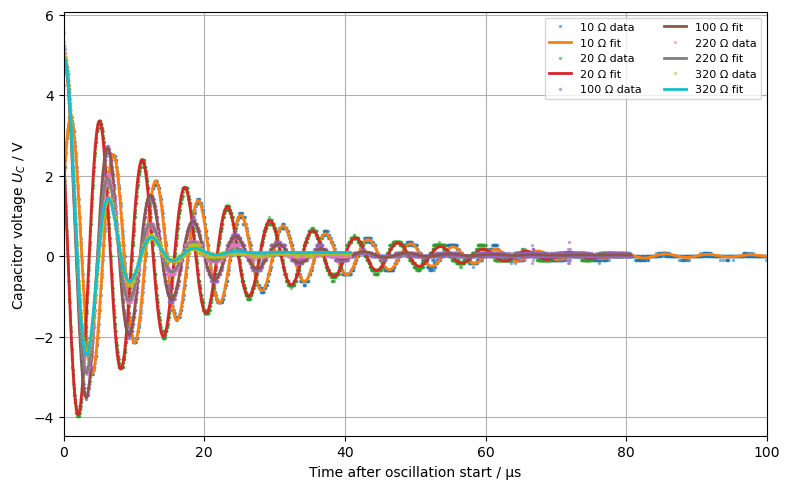

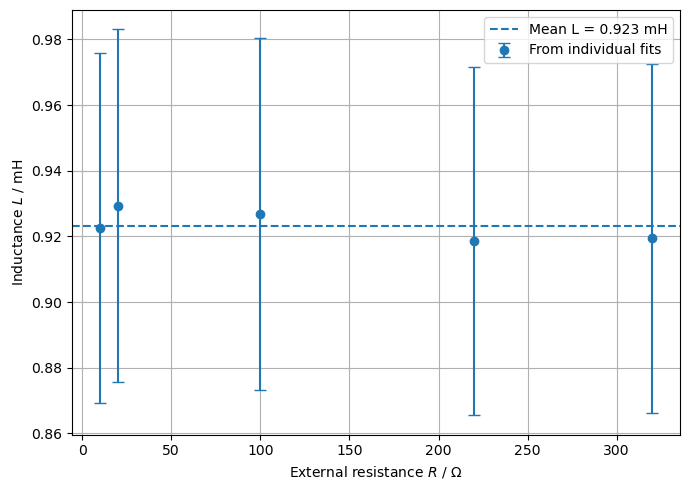

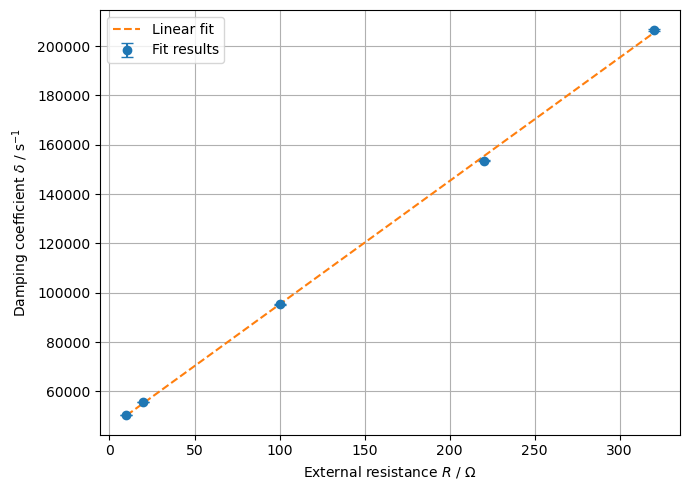


From linear fit delta = a R + b:
a = 4.9995e+02 1/(s Ohm)
b = 4.5306e+04 1/s
L from slope = 1.0001 mH
R_sp from intercept = 90.62 Ohm


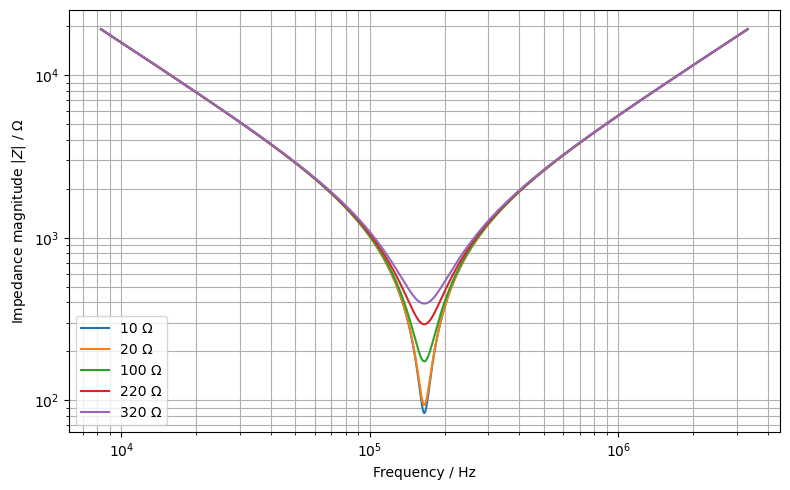

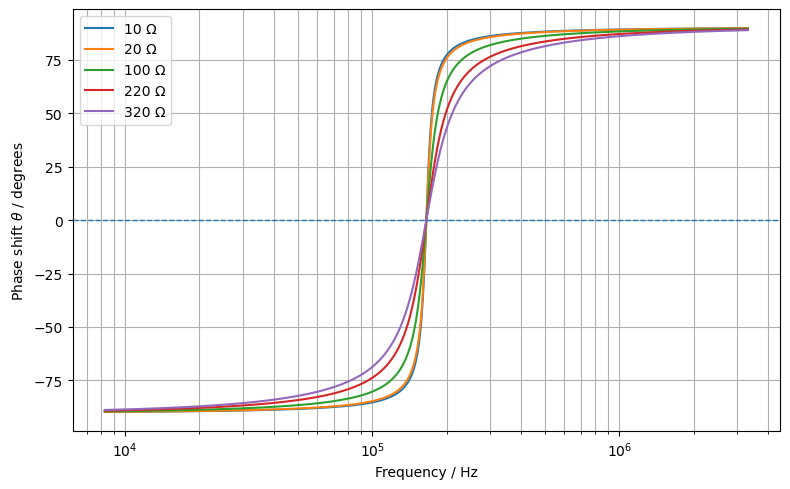

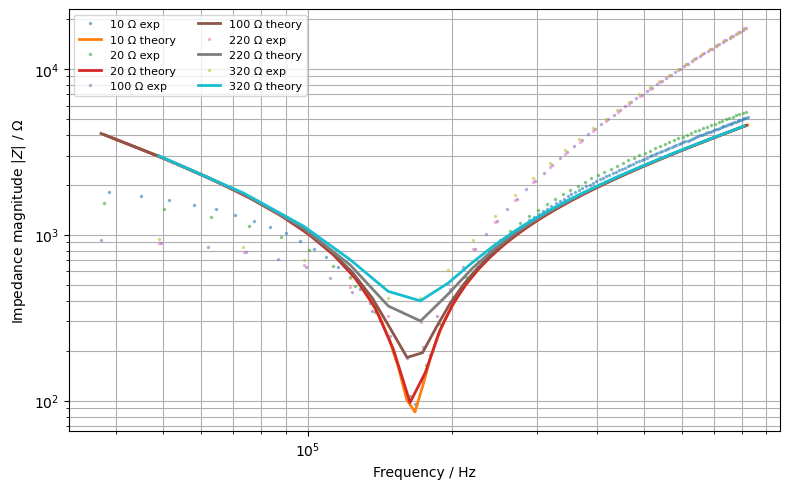

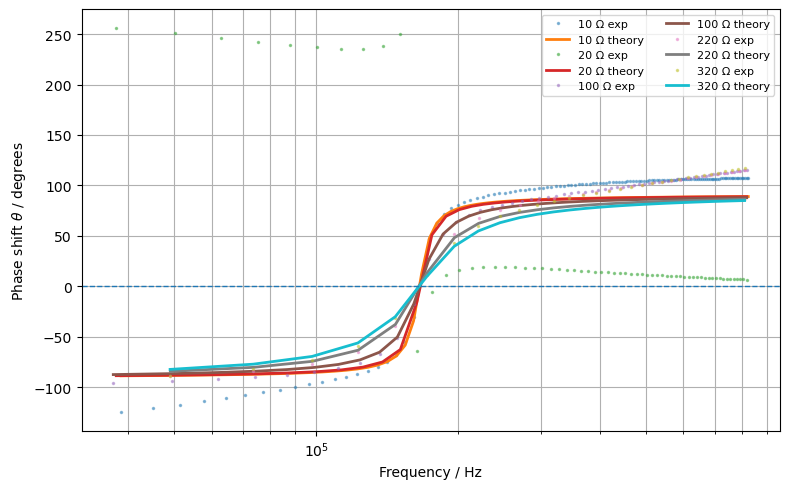


LaTeX table:
\begin{tabular}{llllllll}
\toprule
$R/\Omega$ & $\delta/\mathrm{s}^{-1}$ & $u(\delta)/\mathrm{s}^{-1}$ & $f_d/\mathrm{kHz}$ & $f_0/\mathrm{kHz}$ & $L/\mathrm{mH}$ & $u(L)/\mathrm{mH}$ & $R_\mathrm{sp}/\Omega$ \\
\midrule
10 & 5.05e+04 & 9.69e+01 & 165.51 & 165.70 & 0.923 & 0.053 & 83.2 \\
20 & 5.58e+04 & 9.42e+01 & 164.85 & 165.09 & 0.929 & 0.054 & 83.0 \\
100 & 9.53e+04 & 1.55e+02 & 164.62 & 165.32 & 0.927 & 0.054 & 75.9 \\
220 & 1.53e+05 & 2.13e+02 & 164.26 & 166.06 & 0.919 & 0.053 & 63.4 \\
320 & 2.07e+05 & 2.59e+02 & 162.69 & 165.98 & 0.919 & 0.053 & 61.4 \\
\bottomrule
\end{tabular}


Saved files:
task2_rlc_results.csv
task2_rlc_raw_curves.png
task2_rlc_damped_fits.png
task2_rlc_inductance_values.png
task2_rlc_delta_vs_R.png
task2_rlc_impedance_theory.png
task2_rlc_phase_theory.png
task2_rlc_impedance_fft.png
task2_rlc_phase_fft.png
task2_rlc_latex_table.txt


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

# ============================================================
# Constants
# ============================================================

C = 1e-9                       # F, RLC capacitor
u_C = 0.10 * C / np.sqrt(3)    # assumed 10% capacitor tolerance

R_ch = 22e3                    # Ohm, charging resistor
u_R_ch = 0.05 * R_ch / np.sqrt(3)

V_range = 10.0                 # V, Picoscope Channel A voltage range
ADC_bits = 8
dV = V_range / (2**ADC_bits)
u_V = dV / np.sqrt(12)

files = {
    10: "2_10.csv",
    20: "2_20.csv",
    100: "2_100.csv",
    220: "2_220.csv",
    320: "2_320.csv"
}

# ============================================================
# Helper functions
# ============================================================

def read_picoscope_csv(filename):
    """
    Reads PicoScope CSV files.

    Expected structure:
    Time, Channel A
    (us), (V)

    The function detects the time unit from the second row if possible.
    If detection fails, it assumes microseconds for Task 2.
    """
    raw = pd.read_csv(filename, header=None)

    unit_text = ""
    if raw.shape[0] > 1:
        unit_text = str(raw.iloc[1, 0]).lower()

    df = pd.read_csv(filename, skiprows=[1])

    t_raw = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy()
    V = pd.to_numeric(df.iloc[:, 1], errors="coerce").to_numpy()

    mask = np.isfinite(t_raw) & np.isfinite(V)
    t_raw = t_raw[mask]
    V = V[mask]

    if "ms" in unit_text:
        t = t_raw * 1e-3
    elif "us" in unit_text or "µs" in unit_text:
        t = t_raw * 1e-6
    elif "ns" in unit_text:
        t = t_raw * 1e-9
    else:
        t = t_raw * 1e-6

    return t, V


def rlc_model(t, U_off, A, delta, omega_d, phi):
    """
    Damped oscillation model for capacitor voltage:
    U_C(t) = U_off + A exp(-delta t) cos(omega_d t + phi)
    """
    return U_off + A * np.exp(-delta * t) * np.cos(omega_d * t + phi)


def find_oscillation_start(t, V):
    """
    Finds the approximate start of oscillation using the largest absolute slope.
    """
    dVdt = np.gradient(V, t)
    idx = np.argmax(np.abs(dVdt))
    return idx


def estimate_frequency_from_fft(t, V):
    """
    Estimates the dominant oscillation frequency using FFT.
    """
    dt = np.mean(np.diff(t))
    y = V - np.mean(V)

    freq = np.fft.rfftfreq(len(y), d=dt)
    Y = np.abs(np.fft.rfft(y))

    valid = freq > 0
    freq = freq[valid]
    Y = Y[valid]

    idx = np.argmax(Y)
    return freq[idx]


def fit_rlc_curve(t, V, R):
    """
    Selects the useful oscillation region and fits a damped cosine.
    """
    start_idx = find_oscillation_start(t, V)
    t_start = t[start_idx]

    t2 = t[start_idx:] - t_start
    V2 = V[start_idx:]

    # Use only the first 250 us for fitting to avoid long noisy tails.
    max_time = min(t2.max(), 250e-6)
    mask = (t2 >= 0) & (t2 <= max_time)

    t_fit = t2[mask]
    V_fit = V2[mask]

    if len(t_fit) < 50:
        raise RuntimeError(f"Too few points selected for R = {R} Ohm.")

    U_off_guess = np.median(V_fit[-max(20, len(V_fit)//10):])

    A_guess = V_fit[0] - U_off_guess
    if abs(A_guess) < 0.1:
        A_guess = (np.max(V_fit) - np.min(V_fit)) / 2

    f_guess = estimate_frequency_from_fft(t_fit, V_fit)
    omega_d_guess = 2 * np.pi * f_guess

    # Rough starting values
    L_guess = 0.9e-3
    R_sp_guess = 90
    delta_guess = (R + R_sp_guess) / (2 * L_guess)

    phi_guess = 0.0

    p0 = [U_off_guess, A_guess, delta_guess, omega_d_guess, phi_guess]

    lower = [-20, -20, 1e3, 2 * np.pi * 50e3, -2*np.pi]
    upper = [20, 20, 5e6, 2 * np.pi * 5e6, 2*np.pi]

    popt, pcov = curve_fit(
        rlc_model,
        t_fit,
        V_fit,
        p0=p0,
        bounds=(lower, upper),
        maxfev=100000
    )

    perr = np.sqrt(np.diag(pcov))

    return t_fit, V_fit, popt, perr, t_start


def rlc_impedance(freq, R_total, L, C):
    omega = 2 * np.pi * freq
    return R_total + 1j * (omega * L - 1 / (omega * C))


def calculate_L_and_uncertainty(C, u_C, omega_d, u_omega_d, delta, u_delta):
    """
    Calculates inductance from:
    omega_0^2 = omega_d^2 + delta^2
    L = 1 / (C omega_0^2)
    """
    omega0 = np.sqrt(omega_d**2 + delta**2)
    L = 1 / (C * omega0**2)

    dL_dC = -1 / (C**2 * omega0**2)
    dL_domega_d = -2 * omega_d / (C * omega0**4)
    dL_ddelta = -2 * delta / (C * omega0**4)

    u_L = np.sqrt(
        (dL_dC * u_C)**2 +
        (dL_domega_d * u_omega_d)**2 +
        (dL_ddelta * u_delta)**2
    )

    return L, u_L, omega0


# ============================================================
# Fit all RLC curves
# ============================================================

results = []
data = {}

for R, filename in files.items():

    if not Path(filename).exists():
        raise FileNotFoundError(f"File not found: {filename}")

    t, V = read_picoscope_csv(filename)

    u_R = 0.05 * R / np.sqrt(3)

    t_fit, V_fit, popt, perr, t_start = fit_rlc_curve(t, V, R)

    U_off, A, delta, omega_d, phi = popt
    u_U_off, u_A, u_delta, u_omega_d, u_phi = perr

    L_i, u_L_i, omega0 = calculate_L_and_uncertainty(
        C, u_C, omega_d, u_omega_d, delta, u_delta
    )

    f_d = omega_d / (2 * np.pi)
    f_0 = omega0 / (2 * np.pi)

    results.append({
        "R / Ohm": R,
        "u(R) / Ohm": u_R,
        "delta / 1/s": delta,
        "u(delta) / 1/s": u_delta,
        "omega_d / rad/s": omega_d,
        "u(omega_d) / rad/s": u_omega_d,
        "f_d / kHz": f_d / 1e3,
        "omega_0 / rad/s": omega0,
        "f_0 / kHz": f_0 / 1e3,
        "L / mH": L_i * 1e3,
        "u(L) / mH": u_L_i * 1e3,
        "U_off / V": U_off,
        "A / V": A,
        "phi / rad": phi,
        "t_start / us": t_start * 1e6
    })

    data[R] = {
        "t_raw": t,
        "V_raw": V,
        "t_fit": t_fit,
        "V_fit": V_fit,
        "popt": popt,
        "perr": perr,
        "L": L_i,
        "u_L": u_L_i,
        "omega0": omega0
    }

results_df = pd.DataFrame(results)

# ============================================================
# Mean inductance and coil internal resistance
# ============================================================

L_values = results_df["L / mH"].to_numpy()
u_L_values = results_df["u(L) / mH"].to_numpy()

valid_weights = np.isfinite(u_L_values) & (u_L_values > 0)

if np.all(valid_weights):
    weights = 1 / u_L_values**2
    L_mean_mH = np.sum(weights * L_values) / np.sum(weights)
    u_L_mean_mH_stat = np.sqrt(1 / np.sum(weights))
else:
    L_mean_mH = np.mean(L_values)
    u_L_mean_mH_stat = np.std(L_values, ddof=1) / np.sqrt(len(L_values))

u_L_scatter_mH = np.std(L_values, ddof=1)
u_L_mean_mH = max(u_L_mean_mH_stat, u_L_scatter_mH)

L_mean = L_mean_mH * 1e-3
u_L_mean = u_L_mean_mH * 1e-3

# Estimate coil internal resistance from:
# R_sp = 2 L delta - R
R_sp_values = []
u_R_sp_values = []

for _, row in results_df.iterrows():
    R = row["R / Ohm"]
    u_R = row["u(R) / Ohm"]
    delta = row["delta / 1/s"]
    u_delta = row["u(delta) / 1/s"]

    R_sp = 2 * L_mean * delta - R

    u_R_sp = np.sqrt(
        (2 * delta * u_L_mean)**2 +
        (2 * L_mean * u_delta)**2 +
        u_R**2
    )

    R_sp_values.append(R_sp)
    u_R_sp_values.append(u_R_sp)

results_df["R_sp / Ohm"] = R_sp_values
results_df["u(R_sp) / Ohm"] = u_R_sp_values

R_sp_mean = np.mean(R_sp_values)
u_R_sp_mean = np.std(R_sp_values, ddof=1)

print("Task 2 RLC fit results:")
display(results_df)

print("\nEstimated mean inductance:")
print(f"L = {L_mean_mH:.4f} mH")
print(f"u(L) ≈ {u_L_mean_mH:.4f} mH")

print("\nEstimated coil internal resistance:")
print(f"R_sp = {R_sp_mean:.2f} Ohm")
print(f"scatter ≈ {u_R_sp_mean:.2f} Ohm")

results_df.to_csv("task2_rlc_results.csv", index=False)

# ============================================================
# Plot 1: Raw RLC curves, trimmed to 100 us
# ============================================================

plt.figure(figsize=(8, 5))

for R in files:
    plt.plot(data[R]["t_raw"] * 1e6, data[R]["V_raw"], label=f"{R:g} Ω")

plt.xlabel("Time / µs")
plt.ylabel("Capacitor voltage $U_C$ / V")
plt.xlim(0, 100)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("task2_rlc_raw_curves.png", dpi=300)
plt.show()

# ============================================================
# Plot 2: Damped oscillation fits, trimmed to 100 us
# ============================================================

plt.figure(figsize=(8, 5))

for R in files:
    t_fit = data[R]["t_fit"]
    V_fit = data[R]["V_fit"]
    popt = data[R]["popt"]

    plt.plot(
        t_fit * 1e6,
        V_fit,
        ".",
        markersize=3,
        alpha=0.45,
        label=f"{R:g} Ω data"
    )

    t_smooth = np.linspace(t_fit.min(), t_fit.max(), 2000)
    V_smooth = rlc_model(t_smooth, *popt)

    plt.plot(
        t_smooth * 1e6,
        V_smooth,
        "-",
        linewidth=2,
        label=f"{R:g} Ω fit"
    )

plt.xlabel("Time after oscillation start / µs")
plt.ylabel("Capacitor voltage $U_C$ / V")
plt.xlim(0, 100)
plt.grid(True)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task2_rlc_damped_fits.png", dpi=300)
plt.show()

# ============================================================
# Plot 3: Inductance values
# ============================================================

plt.figure(figsize=(7, 5))

plt.errorbar(
    results_df["R / Ohm"],
    results_df["L / mH"],
    yerr=results_df["u(L) / mH"],
    fmt="o",
    capsize=4,
    label="From individual fits"
)

plt.axhline(
    L_mean_mH,
    linestyle="--",
    label=f"Mean L = {L_mean_mH:.3f} mH"
)

plt.xlabel(r"External resistance $R$ / $\Omega$")
plt.ylabel(r"Inductance $L$ / mH")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("task2_rlc_inductance_values.png", dpi=300)
plt.show()

# ============================================================
# Plot 4: Damping coefficient versus resistance
# ============================================================

plt.figure(figsize=(7, 5))

R_vals = results_df["R / Ohm"].to_numpy()
delta_vals = results_df["delta / 1/s"].to_numpy()
u_delta_vals = results_df["u(delta) / 1/s"].to_numpy()

plt.errorbar(
    R_vals,
    delta_vals,
    yerr=u_delta_vals,
    fmt="o",
    capsize=4,
    label="Fit results"
)

# Linear fit: delta = aR + b
coeffs = np.polyfit(R_vals, delta_vals, 1)
a, b = coeffs

R_line = np.linspace(min(R_vals), max(R_vals), 300)
delta_line = a * R_line + b

plt.plot(R_line, delta_line, "--", label="Linear fit")

L_from_slope = 1 / (2 * a)
R_sp_from_intercept = b / a

plt.xlabel(r"External resistance $R$ / $\Omega$")
plt.ylabel(r"Damping coefficient $\delta$ / s$^{-1}$")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("task2_rlc_delta_vs_R.png", dpi=300)
plt.show()

print("\nFrom linear fit delta = a R + b:")
print(f"a = {a:.4e} 1/(s Ohm)")
print(f"b = {b:.4e} 1/s")
print(f"L from slope = {L_from_slope*1e3:.4f} mH")
print(f"R_sp from intercept = {R_sp_from_intercept:.2f} Ohm")

# ============================================================
# Plot 5: Theoretical RLC impedance magnitude
# ============================================================

plt.figure(figsize=(8, 5))

f0_mean = 1 / (2 * np.pi * np.sqrt(L_mean * C))
freq_theory = np.logspace(np.log10(f0_mean / 20), np.log10(f0_mean * 20), 1000)

for R in files:
    R_total = R + R_sp_mean
    Z = rlc_impedance(freq_theory, R_total, L_mean, C)
    plt.loglog(freq_theory, np.abs(Z), label=f"{R:g} Ω")

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Impedance magnitude $|Z|$ / $\Omega$")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("task2_rlc_impedance_theory.png", dpi=300)
plt.show()

# ============================================================
# Plot 6: Theoretical RLC phase shift
# ============================================================

plt.figure(figsize=(8, 5))

for R in files:
    R_total = R + R_sp_mean
    Z = rlc_impedance(freq_theory, R_total, L_mean, C)
    plt.semilogx(freq_theory, np.angle(Z, deg=True), label=f"{R:g} Ω")

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Frequency / Hz")
plt.ylabel(r"Phase shift $\theta$ / degrees")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("task2_rlc_phase_theory.png", dpi=300)
plt.show()

# ============================================================
# FFT-based impedance and phase analysis
# ============================================================
# The measured signal is capacitor voltage, not current.
# Since Q = C U_C and I = dQ/dt = C dU_C/dt,
# a current-like signal is estimated by differentiating the fitted voltage.
# The FFT comparison is therefore mainly used for qualitative frequency-domain behaviour.

fft_results = {}

for R in files:
    t_fit = data[R]["t_fit"]
    U_off, A, delta, omega_d, phi = data[R]["popt"]

    dt = np.mean(np.diff(t_fit))

    V_smooth = rlc_model(t_fit, *data[R]["popt"])
    V_centered = V_smooth - U_off

    I_signal = C * np.gradient(V_centered, dt)
    I_signal = I_signal - np.mean(I_signal)

    freq = np.fft.rfftfreq(len(I_signal), d=dt)
    Ihat = np.fft.rfft(I_signal) * dt

    valid = freq > 0
    freq = freq[valid]
    Ihat = Ihat[valid]

    R_total = R + R_sp_mean
    Z_theory = rlc_impedance(freq, R_total, L_mean, C)

    # Larger current response corresponds to smaller impedance.
    Z_shape = 1 / np.abs(Ihat)

    resonance_mask = (freq > 0.7 * f0_mean) & (freq < 1.3 * f0_mean)

    if np.sum(resonance_mask) > 3:
        scale = (
            np.median(np.abs(Z_theory[resonance_mask])) /
            np.median(Z_shape[resonance_mask])
        )
    else:
        scale = np.median(np.abs(Z_theory)) / np.median(Z_shape)

    Z_exp_abs = Z_shape * scale

    phase_exp = -np.angle(Ihat, deg=True)

    if np.sum(resonance_mask) > 3:
        phase_offset = (
            np.median(phase_exp[resonance_mask]) -
            np.median(np.angle(Z_theory[resonance_mask], deg=True))
        )
        phase_exp = phase_exp - phase_offset

    fft_results[R] = {
        "freq": freq,
        "Z_exp_abs": Z_exp_abs,
        "phase_exp": phase_exp,
        "Z_theory": Z_theory
    }

# ============================================================
# Plot 7: FFT-based impedance magnitude
# ============================================================

plt.figure(figsize=(8, 5))

for R in files:
    freq = fft_results[R]["freq"]
    Z_exp_abs = fft_results[R]["Z_exp_abs"]
    Z_theory = fft_results[R]["Z_theory"]

    mask = (freq > f0_mean / 5) & (freq < f0_mean * 5)

    plt.loglog(
        freq[mask],
        Z_exp_abs[mask],
        ".",
        markersize=3,
        alpha=0.45,
        label=f"{R:g} Ω exp"
    )

    plt.loglog(
        freq[mask],
        np.abs(Z_theory[mask]),
        "-",
        linewidth=2,
        label=f"{R:g} Ω theory"
    )

plt.xlabel("Frequency / Hz")
plt.ylabel(r"Impedance magnitude $|Z|$ / $\Omega$")
plt.grid(True, which="both")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task2_rlc_impedance_fft.png", dpi=300)
plt.show()

# ============================================================
# Plot 8: FFT-based phase shift
# ============================================================

plt.figure(figsize=(8, 5))

for R in files:
    freq = fft_results[R]["freq"]
    phase_exp = fft_results[R]["phase_exp"]
    Z_theory = fft_results[R]["Z_theory"]

    mask = (freq > f0_mean / 5) & (freq < f0_mean * 5)

    plt.semilogx(
        freq[mask],
        phase_exp[mask],
        ".",
        markersize=3,
        alpha=0.45,
        label=f"{R:g} Ω exp"
    )

    plt.semilogx(
        freq[mask],
        np.angle(Z_theory[mask], deg=True),
        "-",
        linewidth=2,
        label=f"{R:g} Ω theory"
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Frequency / Hz")
plt.ylabel(r"Phase shift $\theta$ / degrees")
plt.grid(True, which="both")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("task2_rlc_phase_fft.png", dpi=300)
plt.show()

# ============================================================
# LaTeX table
# ============================================================

latex_df = results_df.copy()

latex_df["R / Ohm"] = latex_df["R / Ohm"].map(lambda x: f"{x:.0f}")
latex_df["delta / 1/s"] = latex_df["delta / 1/s"].map(lambda x: f"{x:.2e}")
latex_df["u(delta) / 1/s"] = latex_df["u(delta) / 1/s"].map(lambda x: f"{x:.2e}")
latex_df["f_d / kHz"] = latex_df["f_d / kHz"].map(lambda x: f"{x:.2f}")
latex_df["f_0 / kHz"] = latex_df["f_0 / kHz"].map(lambda x: f"{x:.2f}")
latex_df["L / mH"] = latex_df["L / mH"].map(lambda x: f"{x:.3f}")
latex_df["u(L) / mH"] = latex_df["u(L) / mH"].map(lambda x: f"{x:.3f}")
latex_df["R_sp / Ohm"] = latex_df["R_sp / Ohm"].map(lambda x: f"{x:.1f}")

latex_df = latex_df[[
    "R / Ohm",
    "delta / 1/s",
    "u(delta) / 1/s",
    "f_d / kHz",
    "f_0 / kHz",
    "L / mH",
    "u(L) / mH",
    "R_sp / Ohm"
]]

latex_df.columns = [
    r"$R/\Omega$",
    r"$\delta/\mathrm{s}^{-1}$",
    r"$u(\delta)/\mathrm{s}^{-1}$",
    r"$f_d/\mathrm{kHz}$",
    r"$f_0/\mathrm{kHz}$",
    r"$L/\mathrm{mH}$",
    r"$u(L)/\mathrm{mH}$",
    r"$R_\mathrm{sp}/\Omega$"
]

latex_code = latex_df.to_latex(index=False, escape=False)

with open("task2_rlc_latex_table.txt", "w") as f:
    f.write(latex_code)

print("\nLaTeX table:")
print(latex_code)

print("\nSaved files:")
print("task2_rlc_results.csv")
print("task2_rlc_raw_curves.png")
print("task2_rlc_damped_fits.png")
print("task2_rlc_inductance_values.png")
print("task2_rlc_delta_vs_R.png")
print("task2_rlc_impedance_theory.png")
print("task2_rlc_phase_theory.png")
print("task2_rlc_impedance_fft.png")
print("task2_rlc_phase_fft.png")
print("task2_rlc_latex_table.txt")